# Occupancy Fusion: PIR + mmWave Bayes Filter

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Settings

In [2]:
# Recordings (folders containing occ.csv and meta.json)
CAL_RECORDING = "recordings/desk_work_calibration"
TEST_RECORDING = "recordings/desk_work_test"

# Run the filters on 1 s windows (the mmWave only updates about once per second)
WINDOW_S = 1.0

# Ignore this many seconds on each side of a ground-truth change when computing
# statistics (sensor hold times and button timing make transitions ambiguous)
GUARD_S = 3.0

# Rule-based fusion: no evidence for this long means the room is empty
RULE_TIMEOUT_S = 20.0

# Bayes filter settings
P_STAY = 0.995      # P(occupied now | occupied 1 s ago)
P_ENTER = 0.005     # P(occupied now | empty 1 s ago)
P_INIT = 0.05       # Initial P(occupied)
P_MIN = 0.01        # Clamp so no evidence streak pushes p to 0 or 1
P_MAX = 0.99
THRESHOLD = 0.5     # Report "occupied" above this probability

## Helper Functions

In [3]:
def load_recording(path):
    """Load occ.csv and meta.json from a recording folder. Returns (df, meta)."""
    path = Path(path)
    df = pd.read_csv(path / "occ.csv")
    df["t"] = df["t_us"] * 1e-6
    with open(path / "meta.json", encoding="utf-8") as f:
        meta = json.load(f)

    return df, meta


def truth_changes(t, truth):
    """Return the times (s) where the ground truth changes"""
    truth = np.asarray(truth)
    idx = np.flatnonzero(np.diff(truth)) + 1

    return np.asarray(t)[idx]


def to_windows(df, window_s):
    """
    Downsample 10 Hz rows into fixed windows. A sensor counts as 1 if it read 1
    anywhere in the window (so short PIR triggers aren't missed). mmWave is -1
    (missing) only if the whole window had no data.
    """
    win_idx = (df["t"] // window_s).astype(int)
    mm = df["mmwave"].where(df["mmwave"] >= 0)     # -1 -> NaN (missing)
    win = pd.DataFrame({
        "t": win_idx * window_s,
        "pir": df["pir"],
        "mmwave": mm,
        "truth": df["truth"],
    }).groupby(win_idx).agg({"t": "first", "pir": "max", "mmwave": "max",
                             "truth": "last"})
    win["mmwave"] = win["mmwave"].fillna(-1).astype(int)

    return win.reset_index(drop=True)


def guard_mask(t, changes, guard_s):
    """True for samples at least guard_s away from every truth change"""
    t = np.asarray(t)
    mask = np.ones(len(t), dtype=bool)
    for tc in changes:
        mask &= np.abs(t - tc) > guard_s

    return mask

In [4]:
def shade_truth(ax, t, truth):
    """Shade the regions where the room was actually occupied"""
    t = np.asarray(t)
    truth = np.asarray(truth)
    edges = np.flatnonzero(np.diff(np.r_[0, truth, 0]))
    for start, stop in zip(edges[::2], edges[1::2]):
        t_end = t[stop] if stop < len(t) else t[-1]
        ax.axvspan(t[start], t_end, color="0.85", lw=0)


def plot_timeline(t, truth, rows, title=""):
    """
    Plot stacked 0/1 traces (and optionally probabilities) over time, with the
    occupied periods shaded. rows = [(label, values, color), ...]
    """
    fig, axes = plt.subplots(len(rows), 1, sharex=True,
                             figsize=(12, 1.4 * len(rows) + 0.8))
    axes = np.atleast_1d(axes)
    for ax, (label, values, color) in zip(axes, rows):
        values = np.asarray(values, dtype=float)
        shade_truth(ax, t, truth)
        ax.step(t, values, where="post", color=color, lw=1.5)
        if label.startswith("P("):
            ax.axhline(THRESHOLD, color="k", ls="--", lw=0.8)
            ax.set_ylim(-0.05, 1.05)
        else:
            ax.set_ylim(-0.2, 1.2)
            ax.set_yticks([0, 1])
        ax.set_ylabel(label, rotation=0, ha="right", va="center")
    axes[0].set_title(title + "   (gray = occupied)")
    axes[-1].set_xlabel("Time (s)")
    fig.tight_layout()
    plt.show()

## Raw Sensor Data

Each sensor's raw 0/1 output at 10 Hz. Gray regions are when someone was actually in the room (ground truth from the button).

Recording: desk_work-20261018-134348  (no notes)
Duration: 900 s, 9001 rows
Occupied: 54% of samples
mmWave: range 30-240 cm, trig sens 4, keep sens 0
Missing mmWave samples: 0


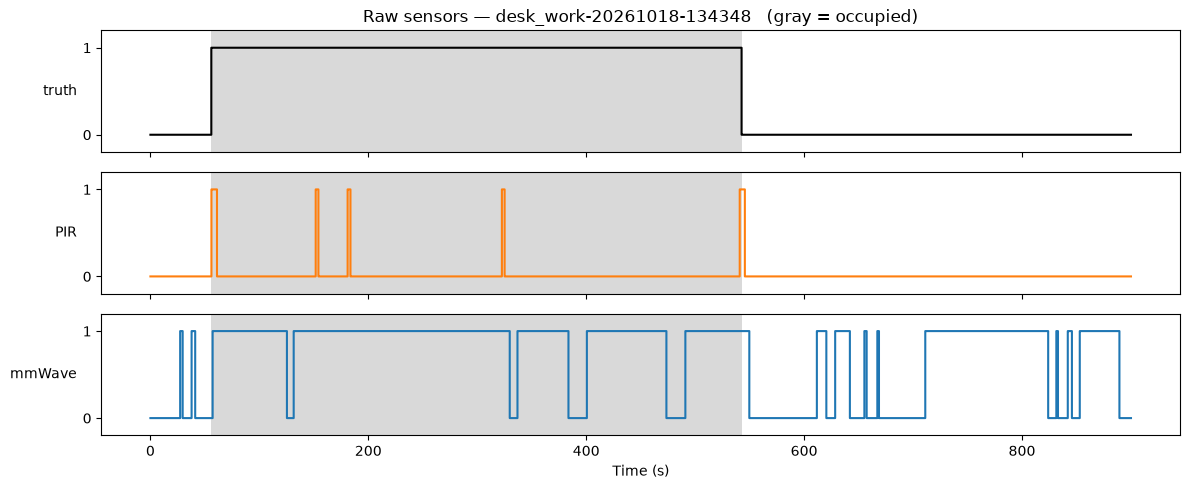

In [5]:
# Load the calibration recording
cal_df, cal_meta = load_recording(CAL_RECORDING)
cfg = cal_meta["config"]

# Print a quick summary
print(f"Recording: {cal_meta['folder']}  ({cal_meta['notes'] or 'no notes'})")
print(f"Duration: {cal_df['t'].iloc[-1]:.0f} s, {len(cal_df)} rows")
print(f"Occupied: {cal_df['truth'].mean():.0%} of samples")
print(f"mmWave: range {cfg['mmwave_min_cm']}-{cfg['mmwave_max_cm']} cm, "
      f"trig sens {cfg['mmwave_trig_sens']}, keep sens {cfg['mmwave_keep_sens']}")
print(f"Missing mmWave samples: {(cal_df['mmwave'] == -1).sum()}")

# Plot raw sensor outputs vs. ground truth
plot_timeline(cal_df["t"], cal_df["truth"], [
    ("truth", cal_df["truth"], "k"),
    ("PIR", cal_df["pir"], "tab:orange"),
    ("mmWave", cal_df["mmwave"].clip(lower=0), "tab:blue"),
], title=f"Raw sensors — {cal_meta['folder']}")

## Sensor Error Rates

We downsample to 1 s windows and drop a few seconds around each ground-truth change, since the sensor hold times and button timing make those moments ambiguous. Then, for each sensor, we count how often it reads 1 when the room is occupied (hit) and when it's empty (false alarm).

In [6]:
def sensor_rates(win, col):
    """Count hits, misses, false alarms, and correct rejections for one sensor"""
    valid = win[win[col] >= 0]
    occ = valid[valid["truth"] == 1]
    emp = valid[valid["truth"] == 0]
    tp = int((occ[col] == 1).sum())
    fn = int((occ[col] == 0).sum())
    fp = int((emp[col] == 1).sum())
    tn = int((emp[col] == 0).sum())

    return {
        "hits (TP)": tp, "misses (FN)": fn,
        "false alarms (FP)": fp, "correct rejections (TN)": tn,
        "hit rate (TPR)": tp / max(tp + fn, 1),
        "miss rate (FNR)": fn / max(tp + fn, 1),
        "false alarm rate (FPR)": fp / max(fp + tn, 1),
    }

In [7]:
# Downsample to 1 s windows and mask out the transitions
cal_win = to_windows(cal_df, WINDOW_S)
cal_changes = truth_changes(cal_df["t"], cal_df["truth"])
cal_mask = guard_mask(cal_win["t"], cal_changes, GUARD_S)
print(f"Truth changes at: {np.round(cal_changes, 1)} s")
print(f"Using {cal_mask.sum()} of {len(cal_win)} windows")

# Error rates for each sensor
rates = pd.DataFrame.from_dict({col: sensor_rates(cal_win[cal_mask], col)
                                for col in ["pir", "mmwave"]}, orient="index")
rates.style.format("{:.1%}", subset=rates.columns[4:])

Truth changes at: [ 55.9 542.6] s
Using 889 of 901 windows


,hits (TP),misses (FN),false alarms (FP),correct rejections (TN),hit rate (TPR),miss rate (FNR),false alarm rate (FPR)
pir,14,467,0,408,2.9%,97.1%,0.0%
mmwave,437,44,197,211,90.9%,9.1%,48.3%


## Calibrate: Likelihoods

The hit rate and false alarm rate *are* the likelihoods the Bayes filter needs:

- P(sensor = 1 | occupied) = hit rate
- P(sensor = 1 | empty) = false alarm rate

We use add-one smoothing, P = (count + 1) / (N + 2), so no likelihood is exactly 0 or 1. A 0 would make one reading infinitely strong evidence.

The likelihood ratio P(reading | occupied) / P(reading | empty) shows how much each reading should move our belief. Above 1 is evidence for occupied; below 1 is evidence for empty.

In [8]:
def compute_likelihoods(win, col):
    """Return (P(1 | occupied), P(1 | empty)) with add-one smoothing"""
    valid = win[win[col] >= 0]
    occ = valid[valid["truth"] == 1]
    emp = valid[valid["truth"] == 0]
    p1_occ = ((occ[col] == 1).sum() + 1) / (len(occ) + 2)
    p1_emp = ((emp[col] == 1).sum() + 1) / (len(emp) + 2)

    return float(p1_occ), float(p1_emp)

In [9]:
# Compute likelihoods from the calibration data
likelihoods = {col: compute_likelihoods(cal_win[cal_mask], col)
               for col in ["pir", "mmwave"]}

# Show likelihoods and likelihood ratios for each possible reading
for col, (p1_occ, p1_emp) in likelihoods.items():
    lr1 = p1_occ / p1_emp
    lr0 = (1 - p1_occ) / (1 - p1_emp)
    print(f"{col:>7}: P(1|occ)={p1_occ:.3f}  P(1|empty)={p1_emp:.3f}  "
          f"LR(reads 1)={lr1:6.2f}  LR(reads 0)={lr0:5.2f}")

    pir: P(1|occ)=0.031  P(1|empty)=0.002  LR(reads 1)= 12.73  LR(reads 0)= 0.97
 mmwave: P(1|occ)=0.907  P(1|empty)=0.483  LR(reads 1)=  1.88  LR(reads 0)= 0.18


## Bayes Filter

A two-state (occupied/empty) discrete Bayes filter, using the same predict-and-correct template as the complementary filter:

- **Predict:** people come and go, so belief drifts according to the transition model (P_STAY, P_ENTER).
- **Update:** each sensor reading multiplies the odds of "occupied" by its likelihood ratio. We work in log-odds, so multiplying becomes adding.

Each sensor also gets an evidence weight (1.0 = treat every reading as fully independent evidence). We'll see why we need it in a moment.

In [10]:
class BayesOccupancyFilter:
    """Two-state (occupied/empty) discrete Bayes filter"""

    def __init__(self, likelihoods, weights, p_stay, p_enter, p_init=0.5,
                 p_min=0.01, p_max=0.99):
        self.likelihoods = likelihoods
        self.weights = weights
        self.p_stay = p_stay
        self.p_enter = p_enter
        self.p_min = p_min
        self.p_max = p_max
        self.p = p_init

    def predict(self):
        """Apply the transition model (occupancy drifts over time)"""
        self.p = self.p * self.p_stay + (1 - self.p) * self.p_enter

        return self.p

    def update(self, readings):
        """Add each sensor's (weighted) evidence. Skip missing readings (-1)."""
        log_odds = np.log(self.p / (1 - self.p))
        for name, z in readings.items():
            if z < 0:
                continue
            p1_occ, p1_emp = self.likelihoods[name]
            if z == 1:
                lr = p1_occ / p1_emp
            else:
                lr = (1 - p1_occ) / (1 - p1_emp)
            log_odds += self.weights[name] * np.log(lr)

        # Convert back to probability and clamp
        self.p = 1 / (1 + np.exp(-log_odds))
        self.p = min(max(self.p, self.p_min), self.p_max)

        return self.p

In [11]:
def run_bayes_filter(win, likelihoods, weights):
    """Run the filter over windowed data. Returns array of P(occupied)."""
    bayes_filter = BayesOccupancyFilter(likelihoods, weights, P_STAY, P_ENTER,
                                        P_INIT, P_MIN, P_MAX)
    ps = []
    for pir, mmwave in zip(win["pir"], win["mmwave"]):
        bayes_filter.predict()
        p = bayes_filter.update({"pir": pir, "mmwave": mmwave})
        ps.append(p)

    return np.array(ps)

### Naive Version: Every Reading Is Independent Evidence

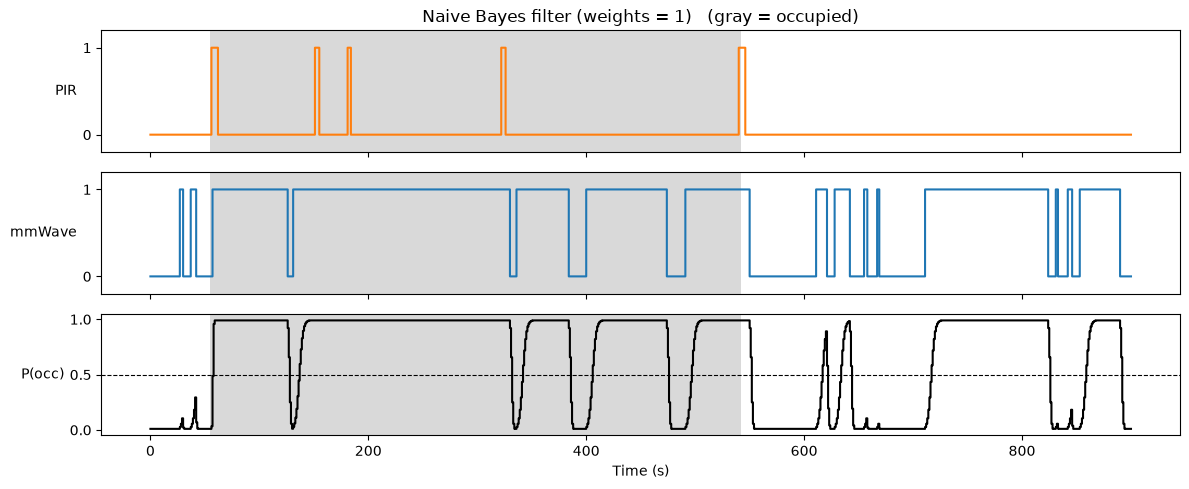

In [12]:
# Run with full weight on every reading
naive_weights = {"pir": 1.0, "mmwave": 1.0}
p_naive = run_bayes_filter(cal_win, likelihoods, naive_weights)

plot_timeline(cal_win["t"], cal_win["truth"], [
    ("PIR", cal_win["pir"], "tab:orange"),
    ("mmWave", cal_win["mmwave"].clip(lower=0), "tab:blue"),
    ("P(occ)", p_naive, "k"),
], title="Naive Bayes filter (weights = 1)")

The naive filter mostly just follows the mmWave. Every second of mmWave reading 0 is counted as fresh evidence, so a short dropout while someone sits still quickly drags the probability down. Every second of a stuck mmWave false positive pushes it back up.

The problem is that consecutive readings aren't independent. The mmWave stays in the same state for tens of seconds at a time, so 30 identical readings carry about as much information as one.

### Evidence Weights From the Data

We can estimate how long one "independent" reading lasts from the average length of each sensor's detection episodes, then count each 1 s reading as only 1/(episode length) of a reading.

In [13]:
def mean_episode_s(values, window_s):
    """Average length (s) of the runs where a sensor reads 1"""
    lengths = []
    n = 0
    for v in np.asarray(values):
        if v == 1:
            n += 1
        elif n:
            lengths.append(n)
            n = 0
    if n:
        lengths.append(n)

    return np.mean(lengths) * window_s if lengths else window_s

    pir: mean episode   4.6 s -> weight 0.217
 mmwave: mean episode  42.8 s -> weight 0.023


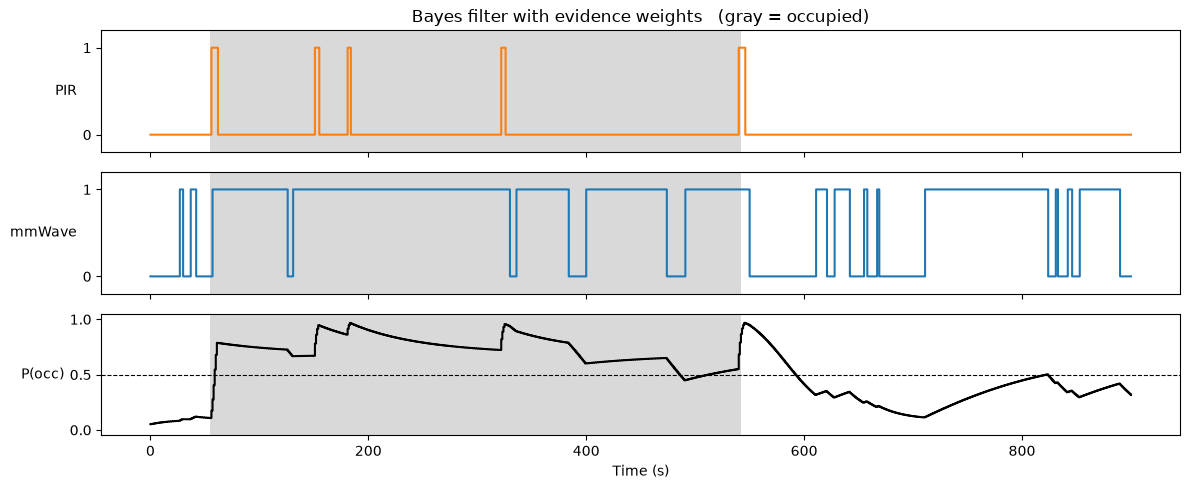

In [14]:
# Weight = 1 / average episode length (capped at 1)
weights = {}
for col in ["pir", "mmwave"]:
    ep_s = mean_episode_s(cal_win[col].clip(lower=0), WINDOW_S)
    weights[col] = min(1.0, WINDOW_S / ep_s)
    print(f"{col:>7}: mean episode {ep_s:5.1f} s -> weight {weights[col]:.3f}")

# Run the weighted filter
p_bayes = run_bayes_filter(cal_win, likelihoods, weights)

plot_timeline(cal_win["t"], cal_win["truth"], [
    ("PIR", cal_win["pir"], "tab:orange"),
    ("mmWave", cal_win["mmwave"].clip(lower=0), "tab:blue"),
    ("P(occ)", p_bayes, "k"),
], title="Bayes filter with evidence weights")

## Rule-Based Fusion (for Comparison)

Same logic as the Arduino demo: only the PIR can mark the room occupied, the mmWave keeps it occupied, and no evidence for RULE_TIMEOUT_S means empty. Run at the full 10 Hz rate, then downsampled to 1 s windows for comparison.

In [15]:
def rule_based_fusion(t, pir, mmwave, timeout_s):
    """PIR sets occupied, mmWave keeps it, timeout clears it"""
    fused = False
    t_evidence = -np.inf
    out = []
    for ti, p, m in zip(t, pir, mmwave):
        if p == 1:
            fused = True
            t_evidence = ti
        elif m == 1:
            t_evidence = ti
        if fused and (ti - t_evidence > timeout_s):
            fused = False
        out.append(int(fused))

    return np.array(out)


def rule_to_windows(df, fused, window_s):
    """Downsample a 10 Hz fused output to windows (1 if occupied at any point)"""
    win_idx = (df["t"] // window_s).astype(int)

    return pd.Series(fused).groupby(win_idx.values).max().values

In [16]:
# Run rule-based fusion on the raw 10 Hz data
rule_10hz = rule_based_fusion(cal_df["t"], cal_df["pir"], cal_df["mmwave"],
                              RULE_TIMEOUT_S)
rule_win = rule_to_windows(cal_df, rule_10hz, WINDOW_S)

## Comparison

How often each approach agrees with the ground truth (transitions excluded). Note that these numbers are *in-sample*: we calibrated on this same recording, so the test set is the honest check.

In [17]:
def score(estimate, truth, mask):
    """Accuracy, miss rate, and false alarm rate of a 0/1 estimate"""
    est = np.asarray(estimate)[mask]
    tru = np.asarray(truth)[mask]
    occ = tru == 1

    return {
        "accuracy": float((est == tru).mean()),
        "miss rate": float((est[occ] == 0).mean()) if occ.any() else np.nan,
        "false alarm rate": float((est[~occ] == 1).mean()) if (~occ).any() else np.nan,
    }


def compare(win, rule_win, p_naive, p_bayes, mask):
    """Score every approach on the same windows"""
    estimates = {
        "PIR only": win["pir"],
        "mmWave only": win["mmwave"].clip(lower=0),
        "Rule-based": rule_win,
        "Bayes (naive)": (p_naive > THRESHOLD).astype(int),
        "Bayes (weighted)": (p_bayes > THRESHOLD).astype(int),
    }

    return pd.DataFrame({name: score(est, win["truth"], mask)
                         for name, est in estimates.items()}).T

In [18]:
# Score every approach on the calibration data
compare(cal_win, rule_win, p_naive, p_bayes, cal_mask).style.format("{:.1%}")

,accuracy,miss rate,false alarm rate
PIR only,47.5%,97.1%,0.0%
mmWave only,72.9%,9.1%,48.3%
Rule-based,97.3%,0.0%,5.9%
Bayes (naive),74.9%,12.5%,40.0%
Bayes (weighted),91.7%,5.4%,11.8%


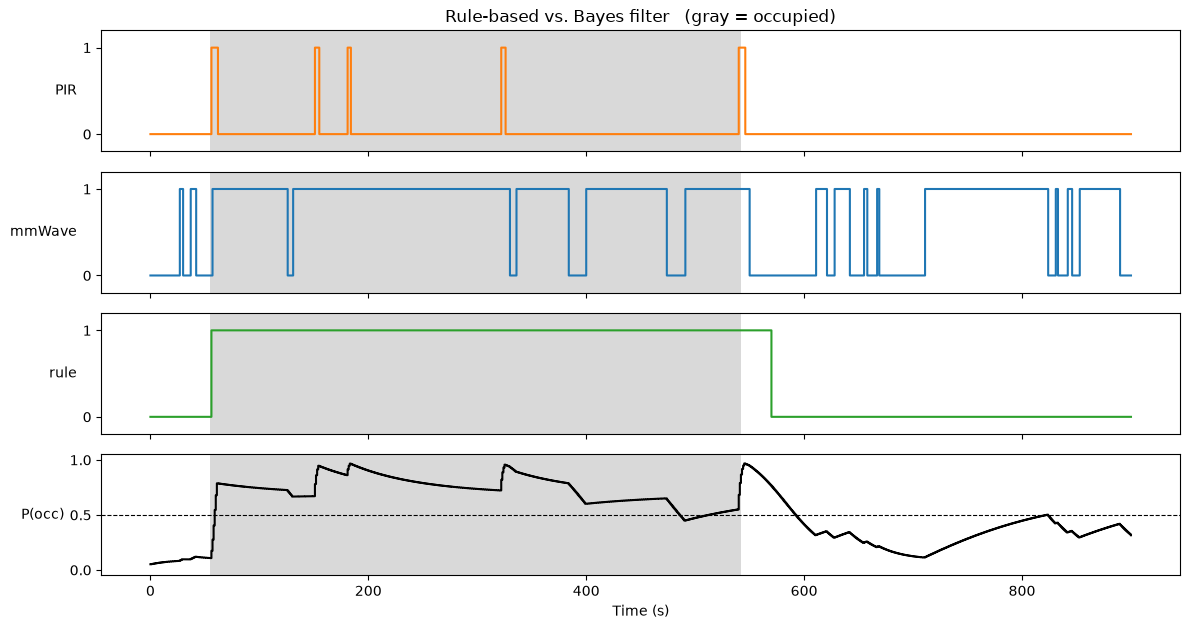

In [19]:
# Plot all fused outputs together
plot_timeline(cal_win["t"], cal_win["truth"], [
    ("PIR", cal_win["pir"], "tab:orange"),
    ("mmWave", cal_win["mmwave"].clip(lower=0), "tab:blue"),
    ("rule", rule_win, "tab:green"),
    ("P(occ)", p_bayes, "k"),
], title="Rule-based vs. Bayes filter")

## Save Calibration

Save the likelihoods, weights, and filter settings so we can apply them to the test set (and port them to the Arduino).

In [20]:
calibration = {
    "recording": cal_meta["folder"],
    "window_s": WINDOW_S,
    "likelihoods": likelihoods,
    "weights": weights,
    "p_stay": P_STAY,
    "p_enter": P_ENTER,
    "p_init": P_INIT,
    "p_min": P_MIN,
    "p_max": P_MAX,
    "threshold": THRESHOLD,
    "rule_timeout_s": RULE_TIMEOUT_S,
}
with open("calibration.json", "w", encoding="utf-8") as f:
    json.dump(calibration, f, indent=2)

# Precompute the weighted log-likelihood ratios for the Arduino port
print("// Weighted log-likelihood ratios (add to log-odds each update)")
for col, (p1_occ, p1_emp) in likelihoods.items():
    w = weights[col]
    llr1 = w * np.log(p1_occ / p1_emp)
    llr0 = w * np.log((1 - p1_occ) / (1 - p1_emp))
    print(f"#define LLR_{col.upper()}_1  {llr1:+.5f}f")
    print(f"#define LLR_{col.upper()}_0  {llr0:+.5f}f")

// Weighted log-likelihood ratios (add to log-odds each update)
#define LLR_PIR_1  +0.55308f
#define LLR_PIR_0  -0.00633f
#define LLR_MMWAVE_1  +0.01472f
#define LLR_MMWAVE_0  -0.04004f


## Test Set

Run everything on a fresh recording using the calibration above (no re-fitting).

Recording: desk_work_test-20261018-140403  (no notes)


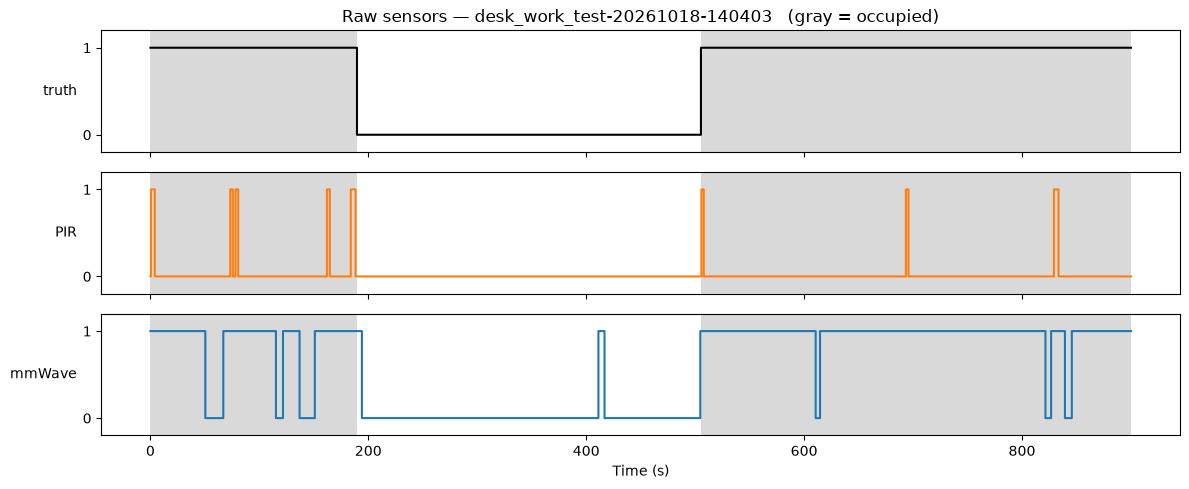

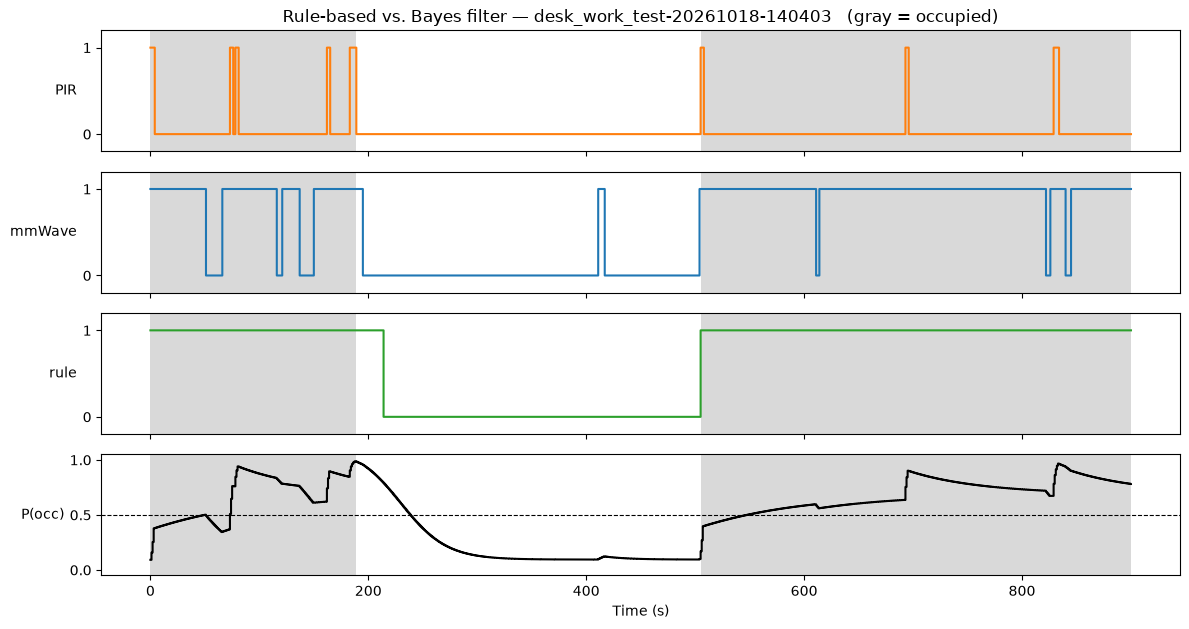

,accuracy,miss rate,false alarm rate
PIR only,37.7%,95.7%,0.0%
mmWave only,94.0%,7.8%,2.6%
Rule-based,97.6%,0.0%,6.8%
Bayes (naive),92.7%,10.5%,1.3%
Bayes (weighted),82.5%,19.0%,14.8%


In [21]:
if TEST_RECORDING is None:
    print("Set TEST_RECORDING in the Settings cell to evaluate on the test set")
else:
    # Load and window the test recording
    test_df, test_meta = load_recording(TEST_RECORDING)
    test_win = to_windows(test_df, WINDOW_S)
    test_changes = truth_changes(test_df["t"], test_df["truth"])
    test_mask = guard_mask(test_win["t"], test_changes, GUARD_S)
    print(f"Recording: {test_meta['folder']}  ({test_meta['notes'] or 'no notes'})")

    # Raw sensors
    plot_timeline(test_df["t"], test_df["truth"], [
        ("truth", test_df["truth"], "k"),
        ("PIR", test_df["pir"], "tab:orange"),
        ("mmWave", test_df["mmwave"].clip(lower=0), "tab:blue"),
    ], title=f"Raw sensors — {test_meta['folder']}")

    # Run all approaches with the calibration from above
    test_rule = rule_to_windows(
        test_df,
        rule_based_fusion(test_df["t"], test_df["pir"], test_df["mmwave"],
                          RULE_TIMEOUT_S),
        WINDOW_S)
    test_p_naive = run_bayes_filter(test_win, likelihoods, naive_weights)
    test_p_bayes = run_bayes_filter(test_win, likelihoods, weights)

    plot_timeline(test_win["t"], test_win["truth"], [
        ("PIR", test_win["pir"], "tab:orange"),
        ("mmWave", test_win["mmwave"].clip(lower=0), "tab:blue"),
        ("rule", test_rule, "tab:green"),
        ("P(occ)", test_p_bayes, "k"),
    ], title=f"Rule-based vs. Bayes filter — {test_meta['folder']}")

    display(compare(test_win, test_rule, test_p_naive, test_p_bayes,
                    test_mask).style.format("{:.1%}"))